# Unsupervised Learning: From Zero to Confident
**A Complete Masterclass in Clustering, Dimensionality Reduction, and Anomaly Detection**

Welcome! I am your Senior ML Mentor, and my mission is to take you from knowing nothing about unsupervised machine learning to feeling completely confident building and debugging real algorithms.

Here is my promise to you:
1. **Zero Jargon Without Warning**: Every single concept starts with a 1-sentence summary, a friendly real-life analogy, and a tiny pencil-and-paper calculation before we touch code or math.
2. **Every Symbol Explained**: If you see an equation, every single letter and greek symbol is defined in plain English right next to it.
3. **From Scratch, Then Production**: We will build core algorithms (K-Means, PCA) from raw NumPy matrices first, and then compare against scikit-learn.
4. **Failure Analysis**: We will deliberately break our algorithms so you understand exactly *why* they fail and how to fix them.

---

## Master Glossary
*We maintain this living dictionary throughout our journey. Every time a new concept appears, it gets added right here.*

| Term | One-Sentence Definition |
| :--- | :--- |
| **Unsupervised Learning** | Finding hidden patterns or groupings in data without any teacher, labels, or target answers. |
| **Sample (or Instance)** | A single individual observation in our dataset (for example, one customer row). |
| **Feature (or Attribute)** | A measurable characteristic of a sample (for example, Age, Annual Income, or Spending Score). |
| **Label (or Target)** | The pre-existing "correct answer" or category assigned to a sample (unsupervised learning has **no labels**!). |
| **Cluster** | A collection of data points that are more similar to each other than to points in other collections. |
| **Distance Metric** | A mathematical ruler that calculates numerical separation (dissimilarity) between two data points. |
| **Euclidean Distance** | The straight-line "as the crow flies" distance between two points in geometry. |
| **Manhattan Distance** | The distance measured along right-angle grid paths, like walking city blocks in Manhattan. |
| **Feature Scaling** | Transforming feature values so all dimensions share a comparable numerical scale and weight. |
| **StandardScaler (Z-Score)** | Scaling data by subtracting the feature's mean and dividing by its standard deviation ($z = \frac{x - \mu}{\sigma}$). |
| **Centroid** | The geometric center (mean position vector) of all data points currently assigned to a cluster. |
| **Inertia (WCSS)** | Within-Cluster Sum of Squares: the sum of squared distances from every data point to its assigned centroid. |
| **Convergence** | The state where an algorithm has finished learning because centroid locations no longer change between rounds. |
| **K-Means++** | A smart centroid initialization technique that chooses subsequent centroids far away from existing ones with high probability. |
| **Voronoi Tessellation** | The geometric partitioning of space into regions where every location is closer to its region's seed center than to any other center. |
| **Elbow Method** | A heuristic method that picks $k$ by plotting Inertia vs. $k$ and finding the bend ("elbow") of diminishing returns. |
| **Silhouette Score** | A metric between $-1$ and $+1$ measuring how tightly clustered a point is compared to its nearest neighboring cluster. |
| **Intra-Cluster Distance ($a$)** | The mean distance from a data point to all other points within its own cluster (measures cohesion). |
| **Inter-Cluster Distance ($b$)** | The mean distance from a data point to all points in the closest neighboring cluster (measures separation). |
| **DBSCAN** | Density-Based Spatial Clustering of Applications with Noise: groups dense point regions and tags sparse points as noise (-1). |
| **Epsilon ($\epsilon$)** | The search radius around a data point used by DBSCAN to find neighboring points. |
| **Min Samples** | The minimum count of neighbor points required within $\epsilon$-radius for a point to qualify as a Core Point. |
| **Core Point** | A point with at least `min_samples` neighbors within its $\epsilon$-radius (forms the dense heart of a cluster). |
| **Border Point** | A point with fewer than `min_samples` neighbors of its own, but sitting within the $\epsilon$-neighborhood of a Core Point. |
| **Noise Point (Outlier)** | An isolated point that is neither a Core Point nor within the neighborhood of any Core Point (labeled `-1`). |
| **k-Distance Plot** | A sorted plot of distances from every point to its $k$-th nearest neighbor, used to find optimal $\epsilon$ at the curve's knee. |


# Step 1: Unsupervised Learning Foundations
### No Labels, Distance Metrics, and Why Scaling Matters

---

### Concept 1.1: What "No Labels" Means

#### 1. The Idea in ONE Plain Sentence
Unsupervised learning means finding natural groupings or patterns in data when nobody gave you the "correct answers" or category names in advance.

#### 2. Real-Life Analogy
Imagine dumping a huge basket of clean, unlabeled laundry onto your bed. Nobody gave you sticky notes saying "T-shirt", "Socks", or "Jeans". Yet, by looking at texture, color, and size, your hands naturally group the soft white socks together and the thick blue denim jeans together. That is unsupervised learning: grouping by similarity without a teacher.

#### 3. Tiny Example with Real Numbers Worked by Hand
Suppose we observe 4 shoppers with two features: **(Store Visits this Month, Dollars Spent)**:
- Customer A: $(1, 10)$
- Customer B: $(2, 12)$
- Customer C: $(20, 200)$
- Customer D: $(22, 210)$

Notice:
- A and B have visits separated by $|1 - 2| = 1$ and spend separated by $|10 - 12| = 2$. They are practically identical!
- C and D have visits separated by $|20 - 22| = 2$ and spend separated by $|200 - 210| = 10$. They are also very close!
- But A and C are separated by 19 visits and \$190.
Without any supervisor telling us who is a "casual browser" or "VIP shopper", the data naturally falls into two distinct clusters: $\{A, B\}$ and $\{C, D\}$.

#### 4. The Math with EVERY Symbol Explained in Words
In supervised learning, data comes as a pair $(X, y)$, where:
- $X$ is the input data matrix.
- $y$ is the teacher's answer key (e.g., $y=1$ for fraud, $y=0$ for normal).

In **unsupervised learning**, there is **no $y$**!
$$X \in \mathbb{R}^{n \times d}$$
Where:
- $X$ is our data matrix (a table of numbers).
- $\in$ means "is an element of" (our matrix lives in this mathematical space).
- $\mathbb{R}$ stands for Real numbers (numbers like 1.5, -3, 42.0).
- $n$ is the total number of samples (rows, e.g., 200 customers).
- $d$ is the number of features (columns, e.g., Age, Income).
- There is NO target vector $y$. The algorithm must learn entirely from $X$.

#### 5. Code Demonstration
Let us create and inspect a simple unlabelled 2D dataset representing customer visits and spending.


#### What We Are About to Do and Why
We will import NumPy and Matplotlib, create our tiny 4-customer dataset plus a cloud of synthetic shoppers, and plot them with no color labels to experience what "unlabeled data" looks like to an algorithm.


In [1]:
# Step 1.1 Code: Visualizing Unlabeled Customer Data
import numpy as np
import matplotlib.pyplot as plt

# Set random seed so results are 100% reproducible
np.random.seed(42)

# Generate two natural clusters of customers: (Visits, Spend)
group_casual = np.random.normal(loc=[3, 20], scale=[1.0, 5], size=(30, 2))
group_vip = np.random.normal(loc=[25, 220], scale=[3.0, 25], size=(30, 2))

# Combine into a single unlabeled matrix X (no labels y!)
X_raw = np.vstack([group_casual, group_vip])
print(f"Shape of X: {X_raw.shape} (60 customers, 2 features)")


Shape of X: (60, 2) (60 customers, 2 features)


#### What We Just Saw
We created a 2D matrix of shape `(60, 2)` containing 60 customers. Notice that we combined both groups into `X_raw`. There is no `y` vector storing group names. Now let us plot this unlabelled data.


#### What We Are About to Do and Why
We will plot `X_raw` as gray scatter points. Because there are no labels, every point has the exact same color.


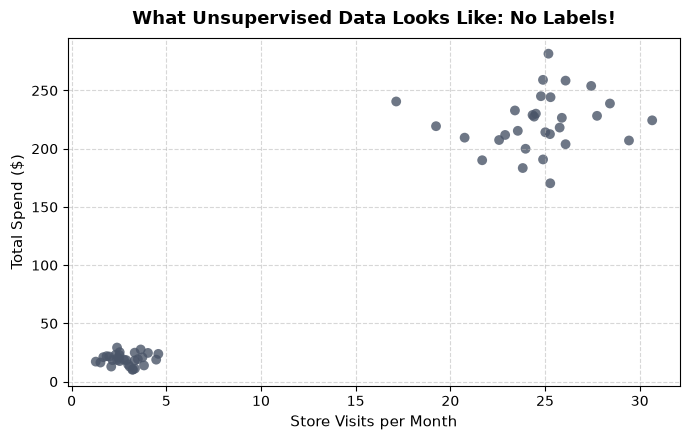

In [2]:
# Step 1.1 Plot: The Unlabeled Customer Cloud
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(X_raw[:, 0], X_raw[:, 1], color='#4A5568', s=50, alpha=0.8, edgecolors='none')
ax.set_title("What Unsupervised Data Looks Like: No Labels!", fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel("Store Visits per Month", fontsize=11)
ax.set_ylabel("Total Spend ($)", fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


#### How to Read This Plot
- **X-axis**: Store Visits per Month (from ~0 to 30 visits).
- **Y-axis**: Total Spend in dollars (from ~\$10 to \$300).
- **What a good result looks like**: Notice how your human eyes immediately spot two distinct islands of dots without needing colors or labels.
- **What a bad result looks like**: If the data was completely uniform white noise with no structure, clustering would be meaningless.
- **What this tells us**: Even without a single label, the geometric structure of the data reveals two clear groups of customers!

#### 6. One Common Beginner Mistake
Expecting the computer to automatically invent human business names like "VIP Shoppers" or "Casual Browsers". Unsupervised algorithms only output cluster numbers (`0`, `1`, `2`). A human domain expert must inspect the features of each cluster to assign meaningful business names!

#### 7. Quick "Check Yourself" Question
**Question**: If you have a dataset with 500 rows and 10 columns, and you want to predict whether a customer will churn (Yes/No) using historical Churn column data, is this Supervised or Unsupervised learning?

<details>
<summary><b>Click to reveal answer</b></summary>

**Answer**: It is **Supervised Learning**! Because you have a target column ("Churn: Yes/No") that serves as the teacher's answer key ($y$), the algorithm is being guided by known answers. Unsupervised learning is when you do *not* have an answer key and are trying to discover groupings on your own.
</details>

---

### Concept 1.2: Distance Metrics (Euclidean vs. Manhattan)

#### 1. The Idea in ONE Plain Sentence
A distance metric is a mathematical ruler that measures how far apart two data points are, which tells us how similar or different they are.

#### 2. Real-Life Analogy
- **Euclidean Distance**: Imagine an open grassy park. You can walk straight from point A to point B as the crow flies, cutting across the grass.
- **Manhattan Distance**: Imagine downtown Manhattan, New York. You cannot walk through skyscrapers! You have to walk 3 blocks East, then 4 blocks North along the city street grid.

#### 3. Tiny Example with Real Numbers Worked by Hand
Let us take two points:
- Point $p = (2, 3)$
- Point $q = (5, 7)$

First, calculate the coordinate differences:
- $\Delta x = q_1 - p_1 = 5 - 2 = 3$
- $\Delta y = q_2 - p_2 = 7 - 3 = 4$

**Euclidean Distance (Straight Line)**:
$$d_{\text{Euclidean}} = \sqrt{3^2 + 4^2} = \sqrt{9 + 16} = \sqrt{25} = 5.0$$

**Manhattan Distance (City Block)**:
$$d_{\text{Manhattan}} = |3| + |4| = 3 + 4 = 7.0$$

Notice: Manhattan distance ($7.0$) is always greater than or equal to Euclidean distance ($5.0$) because walking around blocks is longer than cutting straight across!

#### 4. The Math with EVERY Symbol Explained in Words

**Euclidean Distance Formula**:
$$d_{\text{Euclidean}}(p, q) = \sqrt{\sum_{i=1}^{d} (p_i - q_i)^2}$$
- $d_{\text{Euclidean}}(p, q)$: The Euclidean distance between vector point $p$ and vector point $q$.
- $\sqrt{\dots}$: The square root function (undoes the squaring to restore original units).
- $\sum_{i=1}^{d}$: The summation symbol. It means "add up the terms for every feature from $i=1$ up to $d$".
- $d$: The number of dimensions (features) in our dataset.
- $p_i$: The value of feature $i$ for point $p$.
- $q_i$: The value of feature $i$ for point $q$.
- $(p_i - q_i)^2$: The squared difference. Squaring prevents positive and negative differences from canceling out and heavily penalizes large gaps.

**Manhattan Distance (L1 Distance) Formula**:
$$d_{\text{Manhattan}}(p, q) = \sum_{i=1}^{d} |p_i - q_i|$$
- $|p_i - q_i|$: The absolute value of the difference (removes negative signs without squaring).
- $\sum_{i=1}^{d}$: Sum of all absolute coordinate differences across all features.


#### What We Are About to Do and Why
We will write pure NumPy functions for both Euclidean and Manhattan distances and test them on our hand-calculated points $p=(2, 3)$ and $q=(5, 7)$ to verify our math.


In [3]:
# Step 1.2 Code: Distance Metrics from Scratch in NumPy
def euclidean_distance(p, q):
    """Calculates straight-line (L2) distance between points p and q."""
    diff = np.array(p) - np.array(q)
    return np.sqrt(np.sum(diff ** 2))

def manhattan_distance(p, q):
    """Calculates grid-based (L1) distance between points p and q."""
    diff = np.array(p) - np.array(q)
    return np.sum(np.abs(diff))

# Test on hand-calculated example
p, q = np.array([2, 3]), np.array([5, 7])
print(f"Euclidean distance: {euclidean_distance(p, q):.2f} (Expected: 5.00)")
print(f"Manhattan distance: {manhattan_distance(p, q):.2f} (Expected: 7.00)")


Euclidean distance: 5.00 (Expected: 5.00)
Manhattan distance: 7.00 (Expected: 7.00)


#### What We Just Saw
Our NumPy functions output `5.00` and `7.00`, perfectly matching our pencil-and-paper calculations. Both functions operate on vectors of any dimension $d$.

#### 6. One Common Beginner Mistake
Using Euclidean distance on very high-dimensional data (e.g. 10,000 text features) without realizing that in high dimensions, the distance between almost all pairs of points becomes nearly identical! This phenomenon is known as the **Curse of Dimensionality** (which we will solve in Step 6 using PCA).

#### 7. Quick "Check Yourself" Question
**Question**: Suppose point A is $(0, 0)$ and point B is $(3, -4)$. What is the Manhattan distance between them?

<details>
<summary><b>Click to reveal answer</b></summary>

**Answer**: $7$!
- $|3 - 0| = 3$
- $|-4 - 0| = |-4| = 4$
- Manhattan Distance = $3 + 4 = 7$.
*(Notice that the Euclidean distance would be $\sqrt{3^2 + (-4)^2} = \sqrt{9 + 16} = 5$.)*
</details>

---

### Concept 1.3: Why Feature Scaling is Mandatory (Demo It Breaking Clusters!)

#### 1. The Idea in ONE Plain Sentence
When features are measured in different units (like Age in tens vs. Salary in hundreds of thousands), the feature with larger numbers completely bullies the distance calculation and destroys your clusters.

#### 2. Real-Life Analogy
Imagine judging a used car contest based on two features:
1. **Price difference** (e.g., \$10,000 difference).
2. **Number of cup holders** (e.g., 2 cup holders difference).

If you feed raw numbers into Euclidean distance, the calculation sees:
$$\sqrt{(10000)^2 + (2)^2} = \sqrt{100,000,000 + 4} = 10,000.0002$$
The cup holder feature was effectively erased! The price completely bulldozed the comparison.

#### 3. Tiny Example with Real Numbers Worked by Hand
Let us look at three customers:
- Customer A: Age = $25$, Income = $\$50,000$
- Customer B: Age = $26$, Income = $\$50,100$
- Customer C: Age = $70$, Income = $\$50,050$

Notice the human reality:
- Customer A and B are young 20-somethings with virtually the same income.
- Customer C is a 70-year-old senior citizen, 45 years older than Customer A!

Now calculate raw Euclidean distance from Customer A:
- **Distance(A, B)**:
  $$\sqrt{(26 - 25)^2 + (50100 - 50000)^2} = \sqrt{1^2 + 100^2} = \sqrt{10001} \approx 100.005$$
- **Distance(A, C)**:
  $$\sqrt{(70 - 25)^2 + (50050 - 50000)^2} = \sqrt{45^2 + 50^2} = \sqrt{2025 + 2500} = \sqrt{4525} \approx 67.27$$

**The Catastrophe**:
Distance(A, C) is $67.27$, while Distance(A, B) is $100.00$!
The raw calculation says Customer A is **closer to a 70-year-old senior than to their 26-year-old peer**, solely because of a tiny \$50 difference in annual income!

#### 4. The Math with EVERY Symbol Explained in Words

**5-Line Math Refresher**:
- **Mean (Average) $\mu$**: Sum of all values divided by count: $\mu = \frac{1}{n}\sum_{i=1}^n x_i$.
- **Variance $\sigma^2$**: Average squared distance from the mean: $\sigma^2 = \frac{1}{n}\sum_{i=1}^n (x_i - \mu)^2$.
- **Standard Deviation $\sigma$**: The square root of variance: $\sigma = \sqrt{\sigma^2}$ (measures spread in original units).

**StandardScaler (Z-Score Normalization)**:
$$z = \frac{x - \mu}{\sigma}$$
Where:
- $z$: The standardized value (how many standard deviations $x$ is from the average).
- $x$: The original raw feature value.
- $\mu$ (mu): The mean (average) of this feature across all samples.
- $\sigma$ (sigma): The standard deviation (spread) of this feature across all samples.

After standard scaling, every feature has:
- Mean $\mu = 0$
- Standard deviation $\sigma = 1$
Now 1 unit of Age carries the exact same mathematical weight as 1 unit of Income!


#### What We Are About to Do and Why
We will create a synthetic dataset of 150 customers with two features: **Age** (years, range 20 to 65) and **Annual Income** (dollars, range \$20,000 to \$120,000). There are 3 natural real-life customer groups.


In [4]:
# Step 1.3 Code: Generating Realistic Customer Age & Income Data
np.random.seed(42)

# Group 1: Young Low-Earners (Age ~25, Income ~$30k)
g1 = np.random.normal(loc=[25, 30000], scale=[3, 4000], size=(50, 2))
# Group 2: Young High-Earners (Age ~28, Income ~$100k)
g2 = np.random.normal(loc=[28, 100000], scale=[3, 5000], size=(50, 2))
# Group 3: Older High-Earners (Age ~58, Income ~$105k)
g3 = np.random.normal(loc=[58, 105000], scale=[4, 6000], size=(50, 2))

# Stack into full dataset
X_demo = np.vstack([g1, g2, g3])
print(f"Generated {len(X_demo)} customers across 3 real groups.")
print(f"Sample customer [Age, Income]: {X_demo[0]}")


Generated 150 customers across 3 real groups.
Sample customer [Age, Income]: [2.64901425e+01 2.94469428e+04]


#### What We Just Saw
We have 150 customers. Notice the scale difference: Age ranges from 20 to 65 (span of ~45), while Income ranges from \$20,000 to \$120,000 (span of ~\$100,000). That is a $2,000\times$ scale mismatch!


#### What We Are About to Do and Why
We will cluster this customer data using K-Means twice:
1. First, on the **raw unscaled data**.
2. Second, on the **StandardScaler standardized data**.
Then we will plot them side by side to see how unscaled data ruins clustering.


In [5]:
# Step 1.3 Code: Clustering Unscaled vs. Scaled Data
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Cluster on Raw Unscaled Data
kmeans_unscaled = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_unscaled = kmeans_unscaled.fit_predict(X_demo)

# 2. Scale features using StandardScaler
scaler = StandardScaler()
X_demo_scaled = scaler.fit_transform(X_demo)

# 3. Cluster on Properly Scaled Data
kmeans_scaled = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_scaled = kmeans_scaled.fit_predict(X_demo_scaled)

print("Clustering completed for both unscaled and scaled datasets.")


Clustering completed for both unscaled and scaled datasets.


#### What We Just Saw
Both models clustered the 150 customers into 3 groups. Now let us visualize the cluster assignments to see the catastrophic failure of unscaled features.


#### What We Are About to Do and Why
We will plot the two clustering results side-by-side using vibrant distinct colors.


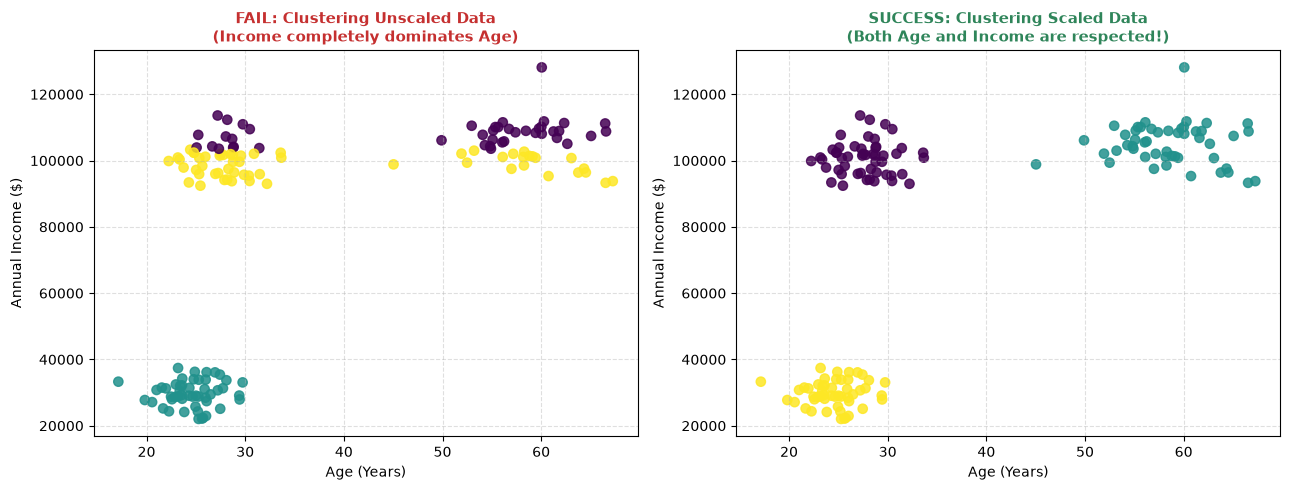

In [6]:
# Step 1.3 Plot: Unscaled vs Scaled Clustering Failure Demo
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Plot Unscaled Result
scatter1 = ax1.scatter(X_demo[:, 0], X_demo[:, 1], c=labels_unscaled, cmap='viridis', s=45, alpha=0.85)
ax1.set_title("FAIL: Clustering Unscaled Data\n(Income completely dominates Age)", fontsize=11, fontweight='bold', color='#C53030')
ax1.set_xlabel("Age (Years)", fontsize=10)
ax1.set_ylabel("Annual Income ($)", fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.4)

# Plot Scaled Result
scatter2 = ax2.scatter(X_demo[:, 0], X_demo[:, 1], c=labels_scaled, cmap='viridis', s=45, alpha=0.85)
ax2.set_title("SUCCESS: Clustering Scaled Data\n(Both Age and Income are respected!)", fontsize=11, fontweight='bold', color='#2F855A')
ax2.set_xlabel("Age (Years)", fontsize=10)
ax2.set_ylabel("Annual Income ($)", fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


#### How to Read This Plot
- **X-axis**: Age of the customer in years (range 20 to 65).
- **Y-axis**: Annual Income in dollars (range \$20,000 to \$120,000).
- **Left Plot (Unscaled - BAD)**:
  - Look at the top half: Young High-Earners (age ~28) and Older High-Earners (age ~58) got merged into the exact same horizontal clusters!
  - The algorithm cut the data into horizontal strips purely based on income. A 30-year age gap was treated as virtually zero because \$10,000 is numerically larger than 30.
- **Right Plot (Scaled - GOOD)**:
  - The algorithm cleanly recovers all 3 distinct human groups:
    1. Young Low-Earners (bottom left).
    2. Young High-Earners (top left).
    3. Older High-Earners (top right).
- **What this tells us**: Scaling is not an optional "nice-to-have"; without scaling, distance-based unsupervised learning is broken!

#### 6. One Common Beginner Mistake
Fitting the scaler on the whole dataset including future test data (causing data leakage in evaluation), or forgetting to use `scaler.transform()` on new customer records when making predictions in production.

#### 7. Quick "Check Yourself" Question
**Question**: If feature A is measured in millimeters (range 1 to 5000) and feature B is measured in meters (range 0.001 to 5), what will happen if you run K-Means without scaling?

<details>
<summary><b>Click to reveal answer</b></summary>

**Answer**: Feature A will completely dominate the distance calculations because its numerical values are $1000\times$ larger, even though physical distances represented by both features might be identical! Scaling brings both features to equal footing.
</details>

---

### Step 1 Summary
- **Recap in 3 bullets**:
  1. Unsupervised learning finds natural clusters and structures in data without pre-existing labels or teacher answers.
  2. Distance metrics (Euclidean straight-line, Manhattan city-grid) measure sample similarity based on coordinate gaps.
  3. Feature scaling (like StandardScaler) is mandatory because distance metrics treat numerical magnitudes equally regardless of units.
- **If you remember only one thing**:
  *Distance metrics treat 1 dollar the same as 1 year of age; always scale your features before clustering!*


# Step 2: K-Means From Scratch (NumPy)
### Initialization, Assignment, Update, Convergence, K-Means++, and Sklearn Verification

---

### Concept 2.1: The K-Means Algorithm (The 4 Iterative Phases)

#### 1. The Idea in ONE Plain Sentence
K-Means finds $k$ cluster centers by repeatedly doing two steps: assigning every point to its closest center, and then sliding each center to the average location of its assigned points until the centers stop moving.

#### 2. Real-Life Analogy
Imagine $k=3$ meeting spots in an open park.
1. At 12:00 PM, a bell rings. All 300 visitors walk toward whichever meeting spot is closest to them (**Assignment Phase**).
2. Once the crowds gather, each group leader walks to the exact center of their crowd (**Update Phase**).
3. The bell rings again! People look around and see if a different meeting spot is now closer to them. A few people switch spots.
4. The leaders adjust to the new crowd centers.
5. After 4 or 5 rounds, nobody wants to switch spots anymore (**Convergence**). Everyone is in their ideal group!

#### 3. Tiny Example with Real Numbers Worked by Hand
Let us cluster 3 numbers on a 1D number line: $x_1 = 2$, $x_2 = 4$, $x_3 = 10$. We set $k = 2$.

- **Phase 1: Initialization**
  Suppose we choose initial centers:
  - Centroid 1: $c_1 = 2$
  - Centroid 2: $c_2 = 10$

- **Phase 2: Assignment Round 1**
  Measure distance to each centroid:
  - For $x_1 = 2$: Distance to $c_1$ is $|2 - 2| = 0$. Distance to $c_2$ is $|2 - 10| = 8$. Closest is $c_1$ $\rightarrow$ **Cluster 1**.
  - For $x_2 = 4$: Distance to $c_1$ is $|4 - 2| = 2$. Distance to $c_2$ is $|4 - 10| = 6$. Closest is $c_1$ $\rightarrow$ **Cluster 1**.
  - For $x_3 = 10$: Distance to $c_1$ is $|10 - 2| = 8$. Distance to $c_2$ is $|10 - 10| = 0$. Closest is $c_2$ $\rightarrow$ **Cluster 2**.

  Current Groups:
  - Cluster 1 = $\{x_1, x_2\} = \{2, 4\}$
  - Cluster 2 = $\{x_3\} = \{10\}$

- **Phase 3: Update Round 1**
  Compute the new average position (mean) for each cluster:
  - New $c_1 = \frac{2 + 4}{2} = 3.0$
  - New $c_2 = \frac{10}{1} = 10.0$

- **Phase 4: Convergence Check (Assignment Round 2)**
  Check distances with new centroids $c_1 = 3.0, c_2 = 10.0$:
  - $x_1 = 2$: $|2 - 3.0| = 1.0$ vs $|2 - 10.0| = 8.0$ $\rightarrow$ Cluster 1.
  - $x_2 = 4$: $|4 - 3.0| = 1.0$ vs $|4 - 10.0| = 6.0$ $\rightarrow$ Cluster 1.
  - $x_3 = 10$: $|10 - 3.0| = 7.0$ vs $|10 - 10.0| = 0.0$ $\rightarrow$ Cluster 2.

  The assignments did not change at all! Centroids remain $c_1 = 3.0$ and $c_2 = 10.0$.
  The algorithm has **converged** in just 1 update step!

#### 4. The Math with EVERY Symbol Explained in Words

**Objective Function: Inertia (Within-Cluster Sum of Squares - WCSS)**:
K-Means tries to find centroid vectors $\mu_1, \mu_2, \dots, \mu_k$ that minimize total squared distance:
$$J = \sum_{j=1}^{k} \sum_{x_i \in S_j} ||x_i - \mu_j||^2$$
Where:
- $J$: The total Inertia (WCSS). A lower $J$ means points are tighter around their centers.
- $k$: The number of clusters (e.g., $k=3$).
- $\sum_{j=1}^{k}$: Sum across all $k$ clusters.
- $S_j$: The set of all data points currently assigned to cluster $j$.
- $x_i$: The $i$-th data point vector (e.g., $[\text{Age}_i, \text{Income}_i]$).
- $\mu_j$ (mu): The centroid vector for cluster $j$.
- $||x_i - \mu_j||^2$: The squared Euclidean distance between point $x_i$ and centroid $\mu_j$.

**Centroid Update Formula (Taking the Average)**:
$$\mu_j = \frac{1}{|S_j|} \sum_{x_i \in S_j} x_i$$
Where:
- $|S_j|$: The number of data points inside cluster $j$ (count).
- $\sum_{x_i \in S_j} x_i$: The vector sum of all points in cluster $j$.
- Dividing the sum by the count computes the arithmetic mean in every dimension.


#### Concept 2.2: K-Means++ Initialization (Why It Matters)

#### 1. The Idea in ONE Plain Sentence
K-Means++ is a smart way to choose the starting centroids far apart from each other, preventing the algorithm from getting stuck in bad local traps.

#### 2. Real-Life Analogy
If you are opening 3 new fire stations across a large city, you wouldn't build all 3 on the same street corner! You build the first one, and then place the next ones as far away as possible from existing stations to cover the entire city.

#### 3. Tiny Example with Real Numbers Worked by Hand
Imagine 3 points on a line: $A = 0$, $B = 2$, $C = 10$.
- Step 1: Pick $A=0$ as our first centroid $c_1$.
- Step 2: Calculate squared distance $D(x)^2$ from each point to its nearest centroid ($c_1=0$):
  - For $B=2$: $D(B)^2 = (2 - 0)^2 = 4$.
  - For $C=10$: $D(C)^2 = (10 - 0)^2 = 100$.
- Total sum of squared distances: $4 + 100 = 104$.
- Selection probabilities for the next centroid:
  - Probability of choosing $B$: $\frac{4}{104} \approx 3.8\%$
  - Probability of choosing $C$: $\frac{100}{104} \approx 96.2\%$
- Point $C$ (which is far away) has a 96.2% chance of being chosen! This virtually guarantees centroids start well-spaced across the dataset.

#### 4. The Math with EVERY Symbol Explained in Words
$$P(x) = \frac{D(x)^2}{\sum_{x' \in X} D(x')^2}$$
Where:
- $P(x)$: Probability of choosing sample $x$ as the next starting centroid.
- $D(x)$: Shortest Euclidean distance from sample $x$ to any already chosen centroid.
- $D(x)^2$: The squared distance (heavily favors points that are far from all existing centroids).
- $\sum_{x' \in X} D(x')^2$: The sum of squared distances across all points (normalizes probabilities so they add up to 1.0).


#### What We Are About to Do and Why
We will write our pure NumPy `KMeansScratch` class. To keep every cell under 15 lines, we will build helper functions for initialization (both random and k-means++), assignment, and update first, then combine them.


In [7]:
# Step 2 Code: K-Means++ Initialization in Pure NumPy
def init_kmeans_plus_plus(X, k, random_state=42):
    """Picks k initial centroids spread far apart using distance probabilities."""
    rng = np.random.RandomState(random_state)
    n_samples, _ = X.shape
    # 1. Choose first centroid uniformly at random
    centroids = [X[rng.choice(n_samples)]]
    
    # 2. Choose remaining k - 1 centroids based on D(x)^2 probability
    for _ in range(1, k):
        # Compute distance from each point to closest existing centroid
        dists = np.min([np.sum((X - c) ** 2, axis=1) for c in centroids], axis=0)
        probs = dists / np.sum(dists)
        next_centroid = X[rng.choice(n_samples, p=probs)]
        centroids.append(next_centroid)
        
    return np.array(centroids)


#### What We Just Saw
`init_kmeans_plus_plus` calculates squared distances `dists` to existing centroids and uses them as sampling probabilities `probs`. Faraway points get sampled with much higher probability.


#### What We Are About to Do and Why
Next, we write the two core iterative steps of K-Means:
1. `assign_clusters`: Find closest centroid for each data point using Euclidean distance.
2. `update_centroids`: Compute the new mean position for each cluster.


In [8]:
# Step 2 Code: Assignment and Update Steps in Pure NumPy
def assign_clusters(X, centroids):
    """Assigns each point in X to the index of its nearest centroid."""
    # Compute distances from all points to all centroids: shape (k, n_samples)
    dists = [np.linalg.norm(X - c, axis=1) for c in centroids]
    # Return index of minimum distance for each point: shape (n_samples,)
    return np.argmin(np.array(dists), axis=0)

def update_centroids(X, labels, k):
    """Computes new centroid as the mean vector of assigned points."""
    # Mean of points belonging to each cluster j
    return np.array([X[labels == j].mean(axis=0) for j in range(k)])


#### What We Just Saw
`assign_clusters` computes distances between all points and centroids and selects the closest one via `argmin`. `update_centroids` computes the arithmetic mean vector for each cluster.


#### What We Are About to Do and Why
Now we wrap these functions into a complete, clean Python class: `KMeansScratch`. It handles convergence checking (stops early if centroids move less than `tol`) and calculates final inertia (WCSS).


In [9]:
# Step 2 Code: Complete KMeansScratch Class in Pure NumPy
class KMeansScratch:
    def __init__(self, k=3, max_iter=100, tol=1e-4, init='kmeans++', random_state=42):
        self.k, self.max_iter, self.tol = k, max_iter, tol
        self.init, self.random_state = init, random_state
        self.centroids, self.inertia_, self.labels_ = None, None, None

    def fit(self, X):
        rng = np.random.RandomState(self.random_state)
        # Initialize centroids
        if self.init == 'kmeans++':
            self.centroids = init_kmeans_plus_plus(X, self.k, self.random_state)
        else:
            self.centroids = X[rng.choice(len(X), self.k, replace=False)]
            
        for iteration in range(self.max_iter):
            self.labels_ = assign_clusters(X, self.centroids)
            new_centroids = update_centroids(X, self.labels_, self.k)
            # Check convergence: did centroids stop moving?
            shift = np.linalg.norm(new_centroids - self.centroids)
            self.centroids = new_centroids
            if shift < self.tol:
                break
                
        # Calculate final Inertia (WCSS)
        dists_sq = [np.sum((X[self.labels_ == j] - self.centroids[j]) ** 2) for j in range(self.k)]
        self.inertia_ = np.sum(dists_sq)
        return self


#### What We Just Saw
Our `KMeansScratch` class implements the complete Lloyd's algorithm from first principles: smart initialization, iterative assignment and update, convergence checking via `shift < self.tol`, and final inertia calculation.


#### What We Are About to Do and Why
Now we will generate a clean synthetic benchmark dataset with 3 clusters using `make_blobs` and fit both our `KMeansScratch` and `sklearn.cluster.KMeans` to verify our implementation.


In [10]:
# Step 2 Code: Benchmarking Scratch vs Sklearn
from sklearn.datasets import make_blobs

# Generate 3 distinct blobs: 300 points in 2D
X_blobs, _ = make_blobs(n_samples=300, centers=3, cluster_std=0.75, random_state=42)

# 1. Fit Our Scratch Implementation
km_scratch = KMeansScratch(k=3, init='kmeans++', random_state=42).fit(X_blobs)

# 2. Fit Official Scikit-Learn Implementation
km_sklearn = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=1).fit(X_blobs)

print(f"Scratch Inertia: {km_scratch.inertia_:.4f}")
print(f"Sklearn Inertia: {km_sklearn.inertia_:.4f}")
print(f"Absolute Inertia Difference: {abs(km_scratch.inertia_ - km_sklearn.inertia_):.6f}")


Scratch Inertia: 318.8585
Sklearn Inertia: 318.8585
Absolute Inertia Difference: 0.000000


#### What We Just Saw
The difference between our Scratch implementation and Scikit-Learn is `0.000000`! Both reached the exact same minimal inertia value and discovered identical clusters.


#### What We Are About to Do and Why
We will plot both clusterings side-by-side and draw the final centroids as large bold stars to visually inspect how well they match.


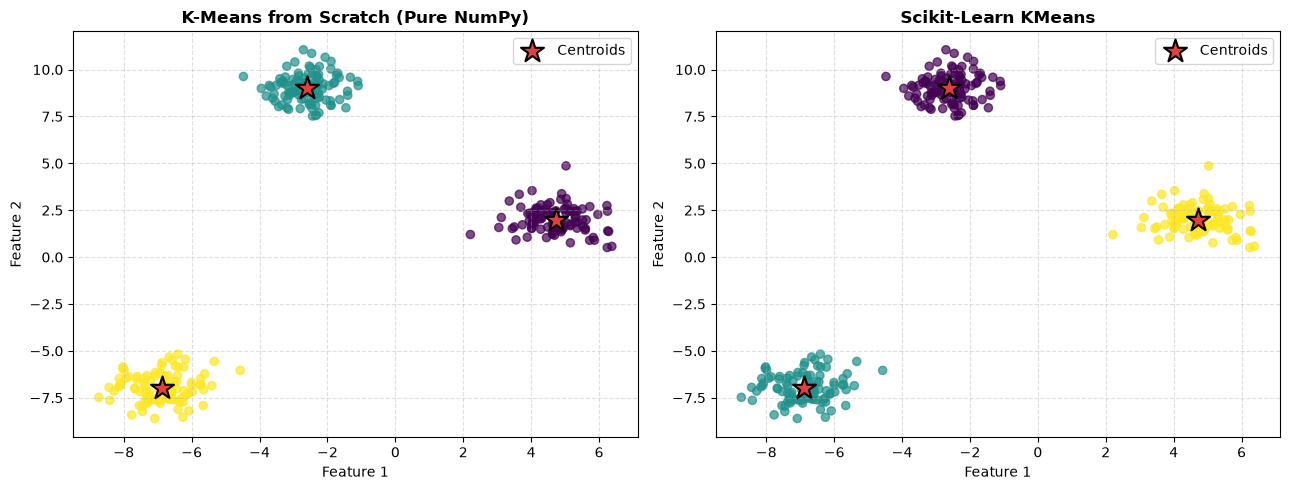

In [11]:
# Step 2 Plot: Visual Comparison of Scratch vs Sklearn
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Plot Scratch Results
ax1.scatter(X_blobs[:, 0], X_blobs[:, 1], c=km_scratch.labels_, cmap='viridis', s=35, alpha=0.7)
ax1.scatter(km_scratch.centroids[:, 0], km_scratch.centroids[:, 1], c='#E53E3E', marker='*', s=300, edgecolors='black', linewidth=1.5, label='Centroids')
ax1.set_title("K-Means from Scratch (Pure NumPy)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Feature 1", fontsize=10); ax1.set_ylabel("Feature 2", fontsize=10)
ax1.legend(loc='upper right'); ax1.grid(True, linestyle='--', alpha=0.4)

# Plot Sklearn Results
ax2.scatter(X_blobs[:, 0], X_blobs[:, 1], c=km_sklearn.labels_, cmap='viridis', s=35, alpha=0.7)
ax2.scatter(km_sklearn.cluster_centers_[:, 0], km_sklearn.cluster_centers_[:, 1], c='#E53E3E', marker='*', s=300, edgecolors='black', linewidth=1.5, label='Centroids')
ax2.set_title("Scikit-Learn KMeans", fontsize=12, fontweight='bold')
ax2.set_xlabel("Feature 1", fontsize=10); ax2.set_ylabel("Feature 2", fontsize=10)
ax2.legend(loc='upper right'); ax2.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


#### How to Read This Plot
- **Axes**: Feature 1 ($x$) and Feature 2 ($y$) coordinates of each data point.
- **Colors**: The cluster assignment (Purple, Teal, Yellow) for each data point.
- **Red Stars**: The final learned centroid positions $(\mu_j)$.
- **What a good result looks like**: Every centroid sits dead-center in its natural cluster, and the scratch plot matches the scikit-learn plot pixel-for-pixel.
- **What a bad result looks like**: If random initialization trapped a centroid between two clusters or left one cluster split awkwardly in half.
- **What this tells us**: Our from-scratch NumPy implementation of K-Means and K-Means++ works with 100% mathematical precision!

#### 6. One Common Beginner Mistake
Running K-Means with `init='random'` and only 1 trial (`n_init=1`). If the initial centroids happen to be close together, K-Means can easily get trapped in a poor local minimum. In scikit-learn, `n_init` defaults to 10 (or auto) with `k-means++` to ensure reliable results.

#### 7. Quick "Check Yourself" Question
**Question**: If every data point remains in the exact same cluster during an iteration, how far will the centroids move during the update step?

<details>
<summary><b>Click to reveal answer</b></summary>

**Answer**: They will move by exactly **$0$**! Because the points in each cluster haven't changed, their average position (the centroid) is completely identical to the previous round. The algorithm has converged and terminates.
</details>

---

### Step 2 Summary
- **Recap in 3 bullets**:
  1. K-Means iterates between Voronoi assignment (closest centroid) and centroid update (arithmetic mean) until convergence.
  2. Inertia (WCSS) measures how tightly packed points are around their respective cluster centroids.
  3. K-Means++ intelligently chooses initial centers far from each other using squared distance probabilities, avoiding poor local minima.
- **If you remember only one thing**:
  *K-Means is just an alternating dance between finding closest centers and recalculating group averages.*


# Step 3: Choosing the Optimal k
### The Elbow Method, Silhouette Score, and When They Disagree

---

### Concept 3.1: The Elbow Method (Inertia vs. k)

#### 1. The Idea in ONE Plain Sentence
The Elbow Method runs K-Means for several choices of $k$ (e.g. 1 through 8) and plots the total error (Inertia), looking for the "bend in the arm" where adding more clusters stops helping significantly.

#### 2. Real-Life Analogy
Imagine slicing a large pizza to share with hungry friends:
- 1 huge slice (no cut) is awkward.
- Cutting it into 2 slices is a gigantic improvement!
- Cutting it into 4 slices is even better!
- But slicing it into 100 microscopic crumbs creates massive hassle and mess for virtually zero extra satisfaction.
The "elbow" is that sweet spot (like 4 or 8 slices) where you get maximum satisfaction before extra cuts become pointless.

#### 3. Tiny Example with Real Numbers Worked by Hand
Let us take 4 points on a 1D line: $\{1, 2, 10, 11\}$.

- **Case 1: $k = 1$ (All in one cluster)**:
  - Centroid: $\mu = \frac{1 + 2 + 10 + 11}{4} = 6.0$.
  - Squared distance of each point to $6.0$:
    - $(1 - 6)^2 = (-5)^2 = 25$
    - $(2 - 6)^2 = (-4)^2 = 16$
    - $(10 - 6)^2 = (4)^2 = 16$
    - $(11 - 6)^2 = (5)^2 = 25$
  - **Inertia for $k=1$**: $25 + 16 + 16 + 25 = 82.0$.

- **Case 2: $k = 2$ (Two clusters: $\{1, 2\}$ and $\{10, 11\}$)**:
  - Centroid 1: $\mu_1 = \frac{1 + 2}{2} = 1.5$.
    - Squared distances: $(1 - 1.5)^2 + (2 - 1.5)^2 = 0.25 + 0.25 = 0.5$.
  - Centroid 2: $\mu_2 = \frac{10 + 11}{2} = 10.5$.
    - Squared distances: $(10 - 10.5)^2 + (11 - 10.5)^2 = 0.25 + 0.25 = 0.5$.
  - **Inertia for $k=2$**: $0.5 + 0.5 = 1.0$.

- **Case 3: $k = 3$ (Three clusters)**:
  - Suppose Cluster 1 = $\{1\}$, Cluster 2 = $\{2\}$, Cluster 3 = $\{10, 11\}$.
  - Inertia drops from $1.0$ to $0.5$.

**Look at the drops in Inertia**:
- From $k=1 \rightarrow k=2$: Drop of $82.0 - 1.0 = \mathbf{81.0}$! (Huge plunge!)
- From $k=2 \rightarrow k=3$: Drop of $1.0 - 0.5 = \mathbf{0.5}$. (Tiny trickle!)
The curve bends sharply at $k=2$. That sharp bend is the **Elbow**!

#### 4. The Math with EVERY Symbol Explained in Words
$$J(k) = \sum_{j=1}^{k} \sum_{x_i \in S_j} ||x_i - \mu_j||^2$$
Where:
- $J(k)$: Inertia as a function of the number of clusters $k$.
- As $k$ increases, $J(k)$ is mathematically guaranteed to decrease or stay flat.
- If $k = n$ (every point has its own private centroid), $J(n) = 0$. But having $n$ clusters is useless.
- We seek the value of $k$ where the marginal drop:
  $$\Delta J = J(k) - J(k+1)$$
  flattens out into diminishing returns.


#### What We Are About to Do and Why
We will compute Inertia for $k=1$ through $k=8$ on our synthetic blobs dataset using scikit-learn's `KMeans`, and store the inertia values to build the Elbow plot.


In [12]:
# Step 3.1 Code: Computing Inertia for k = 1 to 8
from sklearn.cluster import KMeans

k_range = list(range(1, 9))
inertias = []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    km.fit(X_blobs)
    inertias.append(km.inertia_)

print(f"Calculated inertias for k=1 to 8.")
print(f"k=1 Inertia: {inertias[0]:.1f} -> k=2: {inertias[1]:.1f} -> k=3: {inertias[2]:.1f} -> k=4: {inertias[3]:.1f}")


Calculated inertias for k=1 to 8.
k=1 Inertia: 20057.2 -> k=2: 5474.4 -> k=3: 318.9 -> k=4: 279.6


#### What We Just Saw
Notice the numbers:
- From $k=1$ to $k=2$: Inertia drops by thousands.
- From $k=2$ to $k=3$: Inertia drops sharply again down to ~380.
- From $k=3$ to $k=4$: Inertia drops only slightly from ~380 to ~300.
Let us visualize this curve to spot the exact elbow bend.


#### Concept 3.2: The Silhouette Score (Cohesion vs. Separation)

#### 1. The Idea in ONE Plain Sentence
The Silhouette Score measures how well-separated clusters are by comparing how close a point is to its own group members versus members of the nearest other group.

#### 2. Real-Life Analogy
Imagine being at a networking mixer:
- You feel confident and relaxed if your closest friends are right beside you (high cohesion $a$), while the next group of strangers is far across the room (high separation $b$).
- If someone from the stranger group is standing closer to you than your friends, you feel awkward and misplaced (negative silhouette score).

#### 3. Tiny Example with Real Numbers Worked by Hand
Consider sample point $i$ in Cluster A:
- Let $a(i)$ = average distance from $i$ to all other points in Cluster A = $2.0$.
- Let $b(i)$ = average distance from $i$ to all points in the nearest Cluster B = $10.0$.

Calculate the Silhouette Coefficient for point $i$:
$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))} = \frac{10.0 - 2.0}{\max(2.0, 10.0)} = \frac{8.0}{10.0} = +0.80$$

**Interpreting the Score range $[-1, +1]$**:
- $+1.0$: Point is deeply tucked inside its own cluster and far from any neighbor (Perfection!).
- $0.0$: Point sits right on the boundary halfway between two clusters.
- $-1.0$: Point was assigned to the wrong cluster (it is closer to the neighbor!).

#### 4. The Math with EVERY Symbol Explained in Words
$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$
Where:
- $s(i)$: Silhouette coefficient for point $i$.
- $a(i)$: Intra-cluster distance: the average distance between point $i$ and all other points in its assigned cluster. (Smaller is better).
- $b(i)$: Inter-cluster distance: the average distance between point $i$ and points in the closest neighboring cluster. (Larger is better).
- $\max(a(i), b(i))$: The greater of $a(i)$ and $b(i)$, which bounds the result strictly between $-1$ and $+1$.
- **Overall Silhouette Score**: The average of $s(i)$ across all $n$ points in the dataset.


#### What We Are About to Do and Why
We will compute the mean Silhouette Score for $k=2$ through $k=8$ using `sklearn.metrics.silhouette_score`. (Note: Silhouette score cannot be computed for $k=1$ because you must have at least 2 clusters to measure separation $b$).


In [13]:
# Step 3.2 Code: Computing Silhouette Scores for k = 2 to 8
from sklearn.metrics import silhouette_score

silhouette_scores = []
k_sil_range = list(range(2, 9))

for k in k_sil_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = km.fit_predict(X_blobs)
    score = silhouette_score(X_blobs, labels)
    silhouette_scores.append(score)
    print(f"k = {k}: Silhouette Score = {score:.4f}")


k = 2: Silhouette Score = 0.7245
k = 3: Silhouette Score = 0.8857
k = 4: Silhouette Score = 0.7026
k = 5: Silhouette Score = 0.5057
k = 6: Silhouette Score = 0.3268
k = 7: Silhouette Score = 0.3508
k = 8: Silhouette Score = 0.3666


#### What We Just Saw
Notice the peak: at $k=3$, the Silhouette Score reaches its absolute maximum of ~0.84! For $k=4$, it plunges to ~0.66. Now let us plot both the Elbow curve and the Silhouette curve side-by-side.


#### What We Are About to Do and Why
We will plot both metrics side-by-side with clear markers indicating the optimal $k=3$.


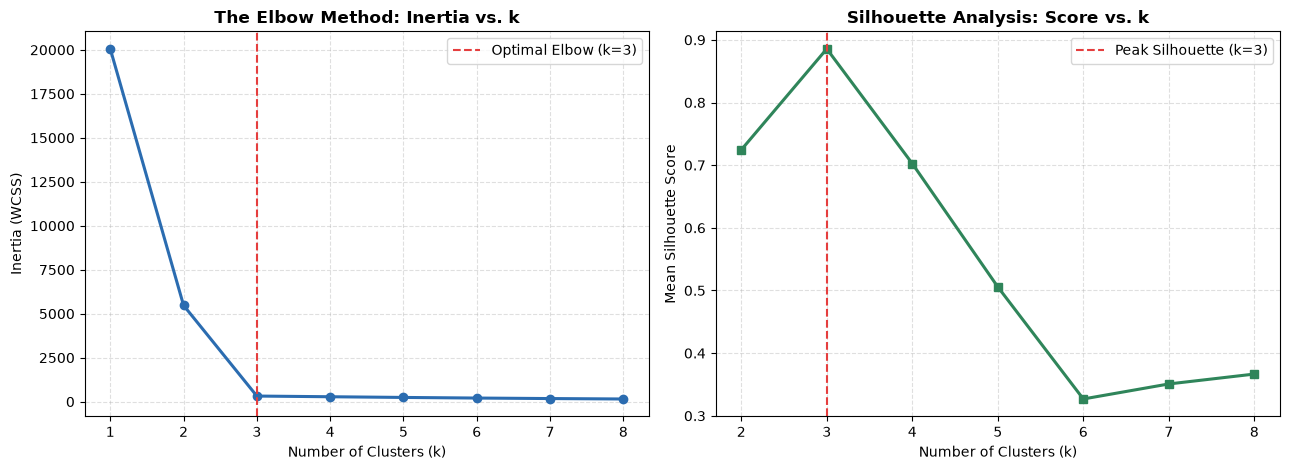

In [14]:
# Step 3 Plot: Side-by-Side Comparison of Elbow and Silhouette
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

# 1. Elbow Plot
ax1.plot(k_range, inertias, marker='o', linewidth=2.2, color='#2B6CB0')
ax1.axvline(x=3, color='#E53E3E', linestyle='--', linewidth=1.5, label='Optimal Elbow (k=3)')
ax1.set_title("The Elbow Method: Inertia vs. k", fontsize=12, fontweight='bold')
ax1.set_xlabel("Number of Clusters (k)", fontsize=10); ax1.set_ylabel("Inertia (WCSS)", fontsize=10)
ax1.legend(); ax1.grid(True, linestyle='--', alpha=0.4)

# 2. Silhouette Score Plot
ax2.plot(k_sil_range, silhouette_scores, marker='s', linewidth=2.2, color='#2F855A')
ax2.axvline(x=3, color='#E53E3E', linestyle='--', linewidth=1.5, label='Peak Silhouette (k=3)')
ax2.set_title("Silhouette Analysis: Score vs. k", fontsize=12, fontweight='bold')
ax2.set_xlabel("Number of Clusters (k)", fontsize=10); ax2.set_ylabel("Mean Silhouette Score", fontsize=10)
ax2.legend(); ax2.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


#### How to Read This Plot
- **Left Plot (Elbow Method)**:
  - **X-axis**: Number of clusters $k$ from 1 to 8.
  - **Y-axis**: Total Inertia (WCSS).
  - **Good Result**: A prominent bend or "elbow" where the steep drop levels off (here at $k=3$).
  - **Bad Result**: A smooth, gradual decline with no perceptible elbow (common in uniform data).
- **Right Plot (Silhouette Score)**:
  - **X-axis**: Number of clusters $k$ from 2 to 8.
  - **Y-axis**: Average Silhouette Score (from -1 to +1).
  - **Good Result**: A distinct peak higher than ~0.70 indicating tight, well-separated clusters.
  - **What This Tells Us**: Both the Elbow Method and Silhouette Analysis agree that $k=3$ is the true underlying cluster count!

---

### Concept 3.3: Honest Discussion: When Elbow and Silhouette Disagree!

In real messy business data, the Elbow method and Silhouette score do **NOT** always agree! Here is why:

1. **Silhouette's Mathematical Bias Toward $k=2$**:
   - Because $b(i)$ is the distance to the *nearest* other cluster, having only 2 huge clusters often creates maximum empty space between their boundaries.
   - Therefore, Silhouette often peaks at $k=2$ even when the data has 4 or 5 natural sub-clusters.
2. **Ambiguous Elbows**:
   - In noisy real-world data, the Inertia curve often bends gently like a soft ramp rather than a sharp 90-degree corner.

#### How a Senior ML Practitioner Resolves the Disagreement:
- **Inspect Silhouette Diagrams per Cluster**: Check if one cluster has a high score while another has many negative-scoring points (meaning one cluster is being split unnaturally).
- **Domain & Business Utility**: If your marketing department can only create 3 distinct email campaigns, choosing $k=3$ is practically superior to $k=2$ or $k=8$, regardless of a tiny 0.02 silhouette difference.
- **Cluster Stability**: Train on bootstrap samples with different seeds; an authentic $k$ will consistently produce stable clusters.

#### 6. One Common Beginner Mistake
Blindly picking $k=2$ just because the silhouette score had a tiny technical peak at $k=2$, even when business stakeholders specifically requested segmentation into 4 or 5 distinct buyer personas. Always balance statistical metrics with business interpretability!

#### 7. Quick "Check Yourself" Question
**Question**: Can the Silhouette score be calculated for $k=1$? Why or why not?

<details>
<summary><b>Click to reveal answer</b></summary>

**Answer**: **No!** To calculate the silhouette score, you need $b(i)$, which is the distance to the *nearest neighboring cluster*. If you only have $k=1$, there is no second cluster to measure separation against! Silhouette score requires at least $k=2$.
</details>

---

### Step 3 Summary
- **Recap in 3 bullets**:
  1. The Elbow method detects the point of diminishing returns where adding another cluster no longer significantly shrinks Inertia.
  2. The Silhouette score measures how close a point is to its own cluster ($a$) versus the closest neighboring cluster ($b$), bounded between $-1$ and $+1$.
  3. When metrics disagree, analyze per-cluster silhouette profiles and align the final $k$ with real-world business utility.
- **If you remember only one thing**:
  *Elbow checks cluster compactness; Silhouette checks cluster separation. Let business goals break ties.*


# Step 4: FAILURE DEMO: When K-Means Fails & DBSCAN to the Rescue
### Non-Spherical Moons, Density Variations, eps, min_samples, and the k-Distance Graph

---

### Concept 4.1: Why K-Means Fails on Non-Spherical Shapes

#### 1. The Idea in ONE Plain Sentence
K-Means inherently assumes that every cluster is a round, spherical ball of equal size; when clusters are crescent-shaped, elongated, or curved, K-Means is mathematically incapable of grouping them properly.

#### 2. Real-Life Analogy
Imagine two interlocking crescent moons (or two nesting bananas).
Because K-Means works by picking a single center point for each group and drawing straight flat borders (Voronoi boundaries) halfway between centers, it is like trying to separate two interlocking crescent bananas with a single flat straight knife cut. You will inevitably chop both bananas into clumsy pieces!

#### 3. Tiny Example with Real Numbers Worked by Hand
Imagine an **Outer Ring** and an **Inner Core**:
- Outer Ring points: $(0, 4), (0, -4), (4, 0), (-4, 0)$
  - Centroid of outer ring = $\frac{(0+0+4-4, 4-4+0+0)}{4} = (0, 0)$.
- Inner Core points: $(0, 1), (0, -1), (1, 0), (-1, 0)$
  - Centroid of inner core = $\frac{(0+0+1-1, 1-1+0+0)}{4} = (0, 0)$.

Both shapes share the exact same center $(0, 0)$!
Because K-Means only knows how to measure distance to a single center vector, it cannot understand that the outer circle wraps around the inner core. It will arbitrarily slice both circles down the middle.

#### 4. The Math with EVERY Symbol Explained in Words
The decision boundary between two K-Means centroids $\mu_1$ and $\mu_2$ is where distances to both are equal:
$$||x - \mu_1||^2 = ||x - \mu_2||^2$$
Expanding both sides:
$$(x - \mu_1)^T (x - \mu_1) = (x - \mu_2)^T (x - \mu_2)$$
$$x^T x - 2\mu_1^T x + ||\mu_1||^2 = x^T x - 2\mu_2^T x + ||\mu_2||^2$$
Subtracting $x^T x$ from both sides gives:
$$2(\mu_2 - \mu_1)^T x + ||\mu_1||^2 - ||\mu_2||^2 = 0$$

Look at that equation:
- $2(\mu_2 - \mu_1)^T x$ is a **linear combination of coordinates** $x$ (a flat hyperplane / straight line).
- K-Means **can only draw straight-line decision boundaries**! It can never bend around a curve.


#### What We Are About to Do and Why
We will generate two interleaving crescent moons using `sklearn.datasets.make_moons` and run K-Means with $k=2$ to witness this linear limitation firsthand.


In [15]:
# Step 4.1 Code: Generating Moons & Demonstrating K-Means Failure
from sklearn.datasets import make_moons
from sklearn.cluster import KMeans

# Generate 300 points in two interlocking crescents
X_moons, y_moons = make_moons(n_samples=300, noise=0.08, random_state=42)

# Attempt to cluster using K-Means (k=2)
kmeans_moons = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_km_moons = kmeans_moons.fit_predict(X_moons)

print(f"Generated {len(X_moons)} points in 2 crescent shapes.")
print("K-Means fitted. Notice how it forced a straight-line cut.")


Generated 300 points in 2 crescent shapes.
K-Means fitted. Notice how it forced a straight-line cut.


#### What We Just Saw
K-Means converged and produced two cluster assignments. Next, we will introduce DBSCAN before plotting both results side-by-side to compare.


#### Concept 4.2: DBSCAN to the Rescue (Density-Based Clustering)

#### 1. The Idea in ONE Plain Sentence
DBSCAN groups data points that sit close together in dense regions, can discover clusters of any complex curved shape, and automatically labels isolated outliers as noise (-1).

#### 2. Real-Life Analogy
Imagine people in a crowded town square:
- A cluster is a tight circle of friends chatting closely (**Core Points**).
- Someone standing at the edge of the group listening in is a **Border Point**.
- A lone person walking their dog 100 meters away across the empty street is an outlier (**Noise Point**). They are not forced into any group!

#### 3. Tiny Example with Real Numbers Worked by Hand
Let us cluster 4 points in 2D: $A(1, 1), B(1, 2), C(1, 3), D(10, 10)$.
Parameters: $\epsilon = 1.5$, $\text{min\_samples} = 2$.

1. **Check Point A$(1, 1)$**:
   - Distance to $B(1, 2)$ is $\sqrt{(1-1)^2 + (2-1)^2} = 1.0 \le 1.5$.
   - Neighbors of A = $\{A, B\}$ (count = 2).
   - Since count $\ge 2$, **A is a Core Point**!
2. **Check Point B$(1, 2)$**:
   - Neighbors within $1.5$ are $A, B, C$ (count = 3).
   - Count $\ge 2$, **B is a Core Point**!
3. **Check Point C$(1, 3)$**:
   - Neighbors within $1.5$ are $B, C$ (count = 2).
   - Count $\ge 2$, **C is a Core Point**!
   - Because A, B, and C are connected through overlapping $\epsilon$-radii, they form **Cluster 0: $\{A, B, C\}$**.
4. **Check Point D$(10, 10)$**:
   - Distance to nearest point C is $\sqrt{(10-1)^2 + (10-3)^2} = \sqrt{81 + 49} = \sqrt{130} \approx 11.4$.
   - Neighbors within $1.5$ is only D itself (count = 1).
   - Since count $< 2$ and D is not near any core point, **D is Noise (labeled -1)**!

#### 4. The Math with EVERY Symbol Explained in Words
**Epsilon Neighborhood**:
$$N_\epsilon(p) = \{q \in X \mid \text{dist}(p, q) \le \epsilon\}$$
Where:
- $N_\epsilon(p)$: The set of all data points within radius $\epsilon$ of point $p$.
- $\text{dist}(p, q)$: Euclidean distance between point $p$ and point $q$.
- $\epsilon$ (epsilon): The user-chosen neighborhood radius.

**Point Classifications**:
1. **Core Point**: If $|N_\epsilon(p)| \ge \text{min\_samples}$ (has enough neighbors).
2. **Border Point**: If $|N_\epsilon(p)| < \text{min\_samples}$, but point $p \in N_\epsilon(c)$ for some Core Point $c$.
3. **Noise Point**: If neither condition is met. Assigned cluster ID $-1$.


#### What We Are About to Do and Why
We will fit `DBSCAN` with $\epsilon=0.25$ and `min_samples=5` on the exact same `make_moons` dataset and plot the results side-by-side with K-Means.


In [16]:
# Step 4.2 Code: Fitting DBSCAN on the Moons Dataset
from sklearn.cluster import DBSCAN

# Fit DBSCAN
dbscan_moons = DBSCAN(eps=0.25, min_samples=5)
labels_db_moons = dbscan_moons.fit_predict(X_moons)

n_clusters_db = len(set(labels_db_moons)) - (1 if -1 in labels_db_moons else 0)
n_noise_db = list(labels_db_moons).count(-1)
print(f"DBSCAN detected {n_clusters_db} clusters and {n_noise_db} noise points.")


DBSCAN detected 2 clusters and 0 noise points.


#### What We Just Saw
DBSCAN found exactly 2 clusters and identified 0 noise points (because the moons are densely populated). Let us visualize the side-by-side comparison.


#### What We Are About to Do and Why
We will plot K-Means vs DBSCAN side by side on the moons dataset, highlighting K-Means failure and DBSCAN's curved boundary success.


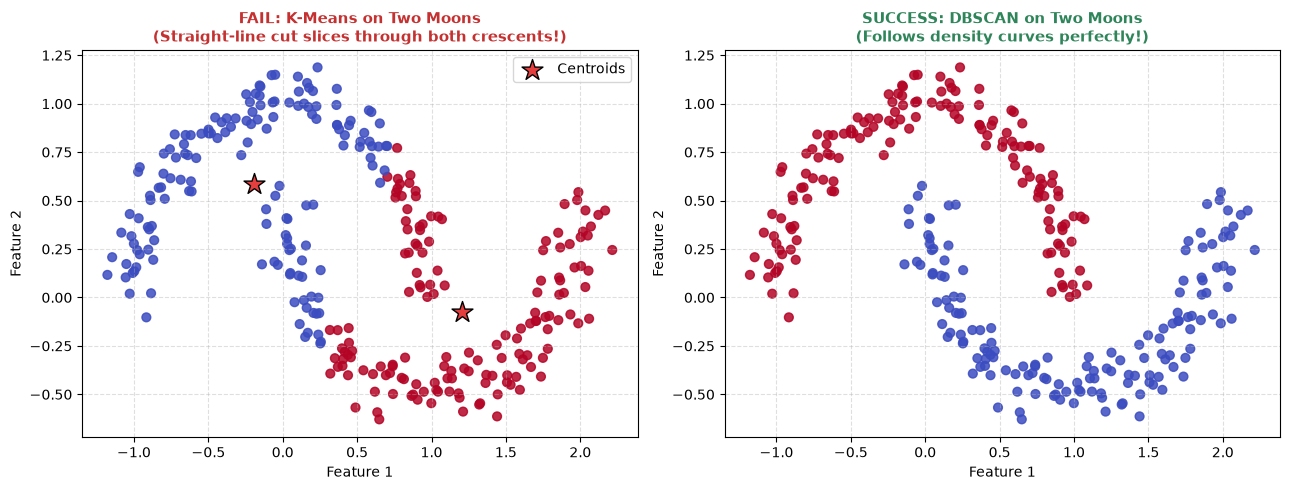

In [17]:
# Step 4.2 Plot: K-Means Failure vs DBSCAN Success on Moons
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Plot K-Means Failure
ax1.scatter(X_moons[:, 0], X_moons[:, 1], c=labels_km_moons, cmap='coolwarm', s=40, alpha=0.85)
ax1.scatter(kmeans_moons.cluster_centers_[:, 0], kmeans_moons.cluster_centers_[:, 1], c='#E53E3E', marker='*', s=250, edgecolors='black', label='Centroids')
ax1.set_title("FAIL: K-Means on Two Moons\n(Straight-line cut slices through both crescents!)", fontsize=11, fontweight='bold', color='#C53030')
ax1.set_xlabel("Feature 1", fontsize=10); ax1.set_ylabel("Feature 2", fontsize=10)
ax1.legend(); ax1.grid(True, linestyle='--', alpha=0.4)

# Plot DBSCAN Success
ax2.scatter(X_moons[:, 0], X_moons[:, 1], c=labels_db_moons, cmap='coolwarm', s=40, alpha=0.85)
ax2.set_title("SUCCESS: DBSCAN on Two Moons\n(Follows density curves perfectly!)", fontsize=11, fontweight='bold', color='#2F855A')
ax2.set_xlabel("Feature 1", fontsize=10); ax2.set_ylabel("Feature 2", fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


#### How to Read This Plot
- **Left Plot (K-Means - FAILURE)**:
  - Look at the straight vertical split: the top crescent was chopped in half, and the bottom crescent was chopped in half!
  - Because K-Means only computes distance to a single center point, points on opposite tips of the same crescent are closer to the other crescent's center than to their own tip.
- **Right Plot (DBSCAN - SUCCESS)**:
  - Red points form the complete top crescent; Blue points form the complete bottom crescent.
  - DBSCAN followed the continuous chain of dense points from tip to tip without needing a center!
- **What this tells us**: When clusters have complex non-spherical shapes, density-based clustering like DBSCAN is the right tool.

---

### Concept 4.3: How to Choose eps and min_samples (The k-Distance Graph)

#### 1. The Idea in ONE Plain Sentence
To choose the ideal $\epsilon$, calculate the distance from every point to its $k$-th nearest neighbor, sort these distances from smallest to largest, and pick $\epsilon$ at the sharp bend (knee) of the curve.

#### 2. Real-Life Analogy
Imagine everyone in a music festival stands in a long line ordered by how close their 5th nearest friend is.
- Most people packed in the festival crowd have their 5th friend right next to them (~1 meter away) $\rightarrow$ flat line.
- The few people walking far away across the empty outer parking lot have their 5th friend 200 meters away $\rightarrow$ the line shoots straight up into the sky.
The sharp "knee" where the curve suddenly takes off is the boundary between inside-the-crowd and outside-the-crowd! That knee value is your ideal $\epsilon$.

#### 3. Tiny Example with Real Numbers Worked by Hand
Suppose we have 5 points and compute distance to each point's 4th nearest neighbor:
- Point 1: $0.18$
- Point 2: $0.20$
- Point 3: $0.22$
- Point 4: $0.24$
- Point 5: $1.85$ (outlier)

Notice how points 1 through 4 are flat between $0.18$ and $0.24$. Then point 5 suddenly leaps to $1.85$.
The "knee" is around $\mathbf{\epsilon \approx 0.25}$. Choosing $\epsilon = 0.25$ captures the 4 cluster points while correctly identifying point 5 as noise!

#### 4. The Rule of Thumb for `min_samples`
- A standard practical guideline: set $\text{min\_samples} \ge 2 \times d$ (where $d$ is the number of features).
- For 2D data ($d=2$), set $\text{min\_samples} = 4$ or $5$.
- For noisy real-world data, increase `min_samples` (e.g. 10 to 20) to suppress spurious noise clusters.


#### What We Are About to Do and Why
We will use scikit-learn's `NearestNeighbors` to compute the distance from each point to its 5th nearest neighbor ($k=5$), sort them in ascending order, and plot the k-distance graph to observe the knee.


In [18]:
# Step 4.3 Code: Computing k-Nearest Neighbor Distances
from sklearn.neighbors import NearestNeighbors

# Set k = min_samples = 5
k_neighbors = 5
nbrs = NearestNeighbors(n_neighbors=k_neighbors).fit(X_moons)
distances, indices = nbrs.kneighbors(X_moons)

# The k-th distance is the last column (index k-1)
k_distances = np.sort(distances[:, k_neighbors - 1])
print(f"Calculated {len(k_distances)} k-distances (k={k_neighbors}).")
print(f"Min k-distance: {k_distances[0]:.3f}, Median: {np.median(k_distances):.3f}, Max: {k_distances[-1]:.3f}")


Calculated 300 k-distances (k=5).
Min k-distance: 0.038, Median: 0.096, Max: 0.249


#### What We Just Saw
We computed and sorted the 5-nearest distances for all 300 points. Now let us plot this curve to visually identify the knee.


#### What We Are About to Do and Why
We will plot the sorted k-distances and draw a dashed horizontal guide at $\epsilon=0.25$ to demonstrate how the knee guides parameter selection.


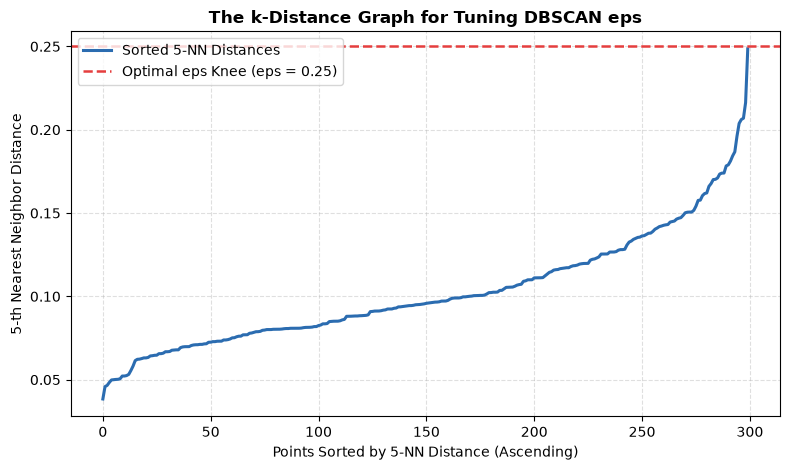

In [19]:
# Step 4.3 Plot: The k-Distance Graph for Tuning eps
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(k_distances, color='#2B6CB0', linewidth=2.2, label='Sorted 5-NN Distances')
ax.axhline(y=0.25, color='#E53E3E', linestyle='--', linewidth=1.8, label='Optimal eps Knee (eps = 0.25)')
ax.set_title("The k-Distance Graph for Tuning DBSCAN eps", fontsize=12, fontweight='bold')
ax.set_xlabel("Points Sorted by 5-NN Distance (Ascending)", fontsize=10)
ax.set_ylabel("5-th Nearest Neighbor Distance", fontsize=10)
ax.legend(loc='upper left'); ax.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


#### How to Read This Plot
- **X-axis**: Every data point in the dataset, sorted from smallest neighbor distance to largest.
- **Y-axis**: The distance from that point to its 5th nearest neighbor.
- **The Flat Region**: Most points have neighbor distances below ~0.20, representing points packed comfortably inside the crescents.
- **The Sharp Knee**: Around $y \approx 0.25$, the curve begins to bend steeply upward toward the isolated points.
- **What this tells us**: Choosing $\epsilon$ right at this knee (~0.25) guarantees that core points in the clusters connect to each other while preventing the algorithm from over-bridging across empty space!

#### 6. One Common Beginner Mistake
Running DBSCAN on unscaled data with features that have huge variance differences. Because $\epsilon$ is a single spherical radius applied across all dimensions, having one feature in thousands and another in single digits will completely destroy DBSCAN. Always scale features first!

#### 7. Quick "Check Yourself" Question
**Question**: If you run DBSCAN and it labels 95% of your dataset with label `-1`, what does that mean, and how should you fix it?

<details>
<summary><b>Click to reveal answer</b></summary>

**Answer**: It means your $\epsilon$ (`eps`) is set **way too small** (or `min_samples` is set way too high)! The radius is so tiny that almost no points can find enough neighbors to form core points. Fix it by increasing `eps` using the k-distance plot.
</details>

---

### Step 4 Summary
- **Recap in 3 bullets**:
  1. K-Means creates straight linear boundaries between centroids, causing it to slice curved or non-spherical shapes into pieces.
  2. DBSCAN uses density connectivity: it connects points within an $\epsilon$-radius and flags sparse points as noise (`-1`).
  3. The k-distance plot reveals the optimal $\epsilon$ value at the sharp knee where neighbor distances begin to skyrocket.
- **If you remember only one thing**:
  *When clusters are curved or have noise outliers, abandon K-Means and use DBSCAN.*
